# PS2 - Transfer Learning with MobileNetV2 (Feature Extraction + Fine-Tuning)
Dataset: TensorFlow Flower Photos (5 classes, downloaded automatically).

## 1. Setup and GPU / VRAM check

In [1]:
import pathlib
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow import keras
from tensorflow.keras import layers

IMG = (160, 160)
BATCH = 32
EPOCHS = 5
FINE_EPOCHS = 5
FINE_TUNE_LAYERS = 30
MIN_FREE_VRAM_MB = 2048
SEED = 42

keras.utils.set_random_seed(SEED)


def require_gpu(min_free_mb):
    gpus = tf.config.list_physical_devices("GPU")
    if not gpus:
        print("=" * 70)
        print("GPU NOT FOUND - this notebook needs a CUDA GPU to run.")
        print(f"Required: at least {min_free_mb} MB of free VRAM.")
        print("How to fix:")
        print("  * Google Colab: Runtime > Change runtime type > T4 GPU")
        print("  * Local PC: install the NVIDIA driver + CUDA-enabled TensorFlow,")
        print("    then restart the kernel and run again.")
        print("=" * 70)
        raise SystemExit("Stopped: no GPU available.")
    for gpu in gpus:
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            pass
    free_mb = None
    try:
        out = subprocess.check_output(
            ["nvidia-smi", "--query-gpu=memory.free", "--format=csv,noheader,nounits"],
            text=True,
        )
        free_mb = max(int(v) for v in out.split())
    except Exception:
        print("Note: could not query free VRAM via nvidia-smi; continuing.")
    if free_mb is not None and free_mb < min_free_mb:
        print("=" * 70)
        print(f"NOT ENOUGH FREE VRAM - found {free_mb} MB, need {min_free_mb} MB.")
        print("Close other programs using the GPU (games, other notebooks),")
        print("then restart the kernel and run again.")
        print("=" * 70)
        raise SystemExit("Stopped: insufficient free VRAM.")
    return free_mb


free_vram = require_gpu(MIN_FREE_VRAM_MB)

policy = "float32"
try:
    cc = tf.config.experimental.get_device_details(
        tf.config.list_physical_devices("GPU")[0]
    ).get("compute_capability")
    major = cc[0] if isinstance(cc, (tuple, list)) else int(float(cc))
    if major >= 7:
        policy = "mixed_float16"
except Exception:
    policy = "mixed_float16"
keras.mixed_precision.set_global_policy(policy)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU")[0].name)
if free_vram is not None:
    print(f"Free VRAM: {free_vram} MB (minimum {MIN_FREE_VRAM_MB} MB)")
print("Compute policy:", keras.mixed_precision.global_policy().name)

TensorFlow: 2.21.0
GPU: /physical_device:GPU:0
Free VRAM: 14910 MB (minimum 2048 MB)
Compute policy: mixed_float16


## 2. Dataset

In [2]:
path = keras.utils.get_file(
    "flower_photos.tgz",
    "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz",
    extract=True,
)
data_dir = next(pathlib.Path(path).parent.rglob("daisy")).parent
print("Data directory:", data_dir)

train_ds = keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="training", seed=SEED,
    image_size=IMG, batch_size=BATCH, label_mode="int",
)
val_ds = keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="validation", seed=SEED,
    image_size=IMG, batch_size=BATCH, label_mode="int",
)
class_names = train_ds.class_names
num_classes = len(class_names)
print("Classes:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().shuffle(1000, seed=SEED).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Data directory: /root/.keras/datasets/flower_photos_extracted/flower_photos
Found 3670 files belonging to 5 classes.
Using 2936 files for training.
Found 3670 files belonging to 5 classes.
Using 734 files for validation.
Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']


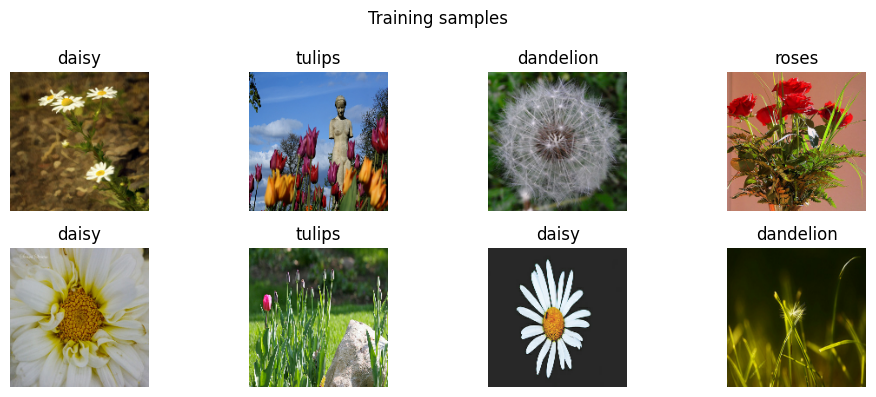

In [3]:
plt.figure(figsize=(10, 4))
for images, labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.suptitle("Training samples")
plt.tight_layout()
plt.show()

## 3. Model - MobileNetV2 with a custom classification head

In [4]:
base = keras.applications.MobileNetV2(
    input_shape=IMG + (3,), include_top=False, weights="imagenet"
)
base.trainable = False

inputs = keras.Input(shape=IMG + (3,))
x = layers.RandomFlip("horizontal")(inputs)
x = layers.RandomRotation(0.1)(x)
x = layers.RandomZoom(0.1)(x)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(num_classes, activation="softmax", dtype="float32")(x)
model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
print(f"Total parameters: {model.count_params():,}")
print(f"Trainable parameters (stage 1): {trainable:,}")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total parameters: 2,264,389
Trainable parameters (stage 1): 6,405


## 4. Stage 1 - Feature extraction (base frozen)

In [5]:
early_stop_1 = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=2, restore_best_weights=True
)
h1 = model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS,
    callbacks=[early_stop_1], verbose=2,
)

Epoch 1/5
92/92 - 19s - 206ms/step - accuracy: 0.6546 - loss: 0.9261 - val_accuracy: 0.8079 - val_loss: 0.5434
Epoch 2/5
92/92 - 4s - 38ms/step - accuracy: 0.8358 - loss: 0.4604 - val_accuracy: 0.8283 - val_loss: 0.4489
Epoch 3/5
92/92 - 3s - 34ms/step - accuracy: 0.8634 - loss: 0.3846 - val_accuracy: 0.8406 - val_loss: 0.4356
Epoch 4/5
92/92 - 3s - 34ms/step - accuracy: 0.8764 - loss: 0.3460 - val_accuracy: 0.8501 - val_loss: 0.4157
Epoch 5/5
92/92 - 3s - 34ms/step - accuracy: 0.8862 - loss: 0.3184 - val_accuracy: 0.8638 - val_loss: 0.3728


## 5. Stage 2 - Fine-tuning (top 30 layers, very low learning rate)

In [6]:
base.trainable = True
for layer in base.layers[:-FINE_TUNE_LAYERS]:
    layer.trainable = False
for layer in base.layers[-FINE_TUNE_LAYERS:]:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
trainable = sum(tf.size(w).numpy() for w in model.trainable_weights)
print(f"Trainable parameters (stage 2): {trainable:,}")

early_stop_2 = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=2, restore_best_weights=True
)
h2 = model.fit(
    train_ds, validation_data=val_ds, epochs=FINE_EPOCHS,
    callbacks=[early_stop_2], verbose=2,
)

Trainable parameters (stage 2): 1,517,125
Epoch 1/5
92/92 - 18s - 197ms/step - accuracy: 0.9019 - loss: 0.2832 - val_accuracy: 0.8651 - val_loss: 0.3675
Epoch 2/5
92/92 - 4s - 39ms/step - accuracy: 0.9060 - loss: 0.2504 - val_accuracy: 0.8706 - val_loss: 0.3575
Epoch 3/5
92/92 - 4s - 39ms/step - accuracy: 0.9135 - loss: 0.2383 - val_accuracy: 0.8760 - val_loss: 0.3337
Epoch 4/5
92/92 - 4s - 42ms/step - accuracy: 0.9278 - loss: 0.2064 - val_accuracy: 0.8801 - val_loss: 0.3385
Epoch 5/5
92/92 - 4s - 39ms/step - accuracy: 0.9278 - loss: 0.1982 - val_accuracy: 0.8883 - val_loss: 0.3164


## 6. Evaluation

Validation accuracy: 0.8883  Validation loss: 0.3164


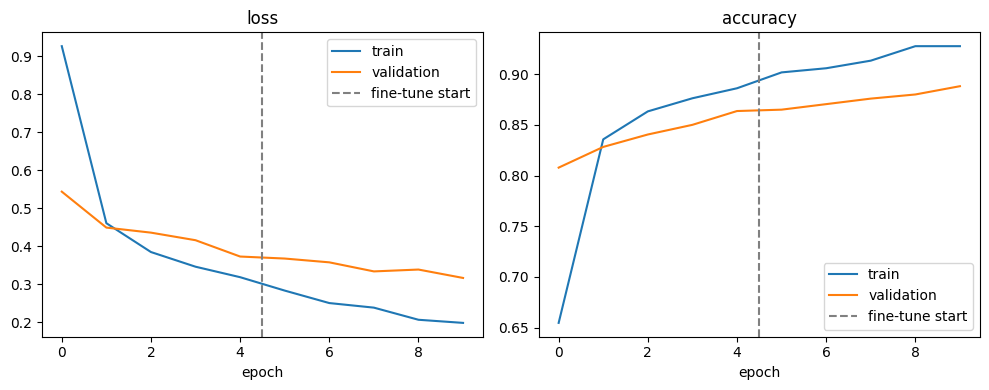

In [7]:
loss, acc = model.evaluate(val_ds, verbose=0)
print(f"Validation accuracy: {acc:.4f}  Validation loss: {loss:.4f}")

hist = {k: h1.history[k] + h2.history[k] for k in h1.history}
n1 = len(h1.history["loss"])
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(["loss", "accuracy"]):
    ax[i].plot(hist[metric], label="train")
    ax[i].plot(hist["val_" + metric], label="validation")
    ax[i].axvline(n1 - 0.5, color="gray", linestyle="--", label="fine-tune start")
    ax[i].set_title(metric)
    ax[i].set_xlabel("epoch")
    ax[i].legend()
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

       daisy     0.8547    0.9346    0.8929       107
   dandelion     0.9362    0.9215    0.9288       191
       roses     0.8240    0.8655    0.8443       119
  sunflowers     0.9091    0.8889    0.8989       135
      tulips     0.8895    0.8407    0.8644       182

    accuracy                         0.8883       734
   macro avg     0.8827    0.8902    0.8858       734
weighted avg     0.8896    0.8883    0.8884       734



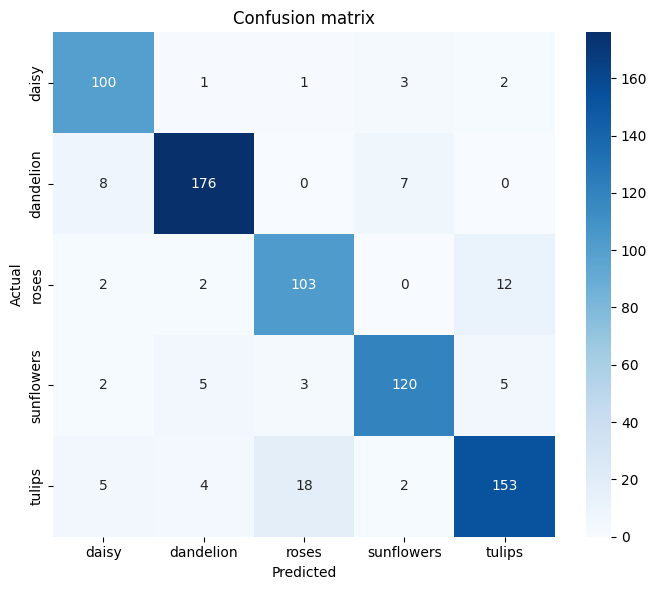

In [8]:
y_true = np.concatenate([labels.numpy() for _, labels in val_ds])
y_pred = model.predict(val_ds, verbose=0).argmax(axis=1)
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

plt.figure(figsize=(7, 6))
sns.heatmap(
    confusion_matrix(y_true, y_pred), annot=True, fmt="d", cmap="Blues",
    xticklabels=class_names, yticklabels=class_names,
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix")
plt.tight_layout()
plt.show()

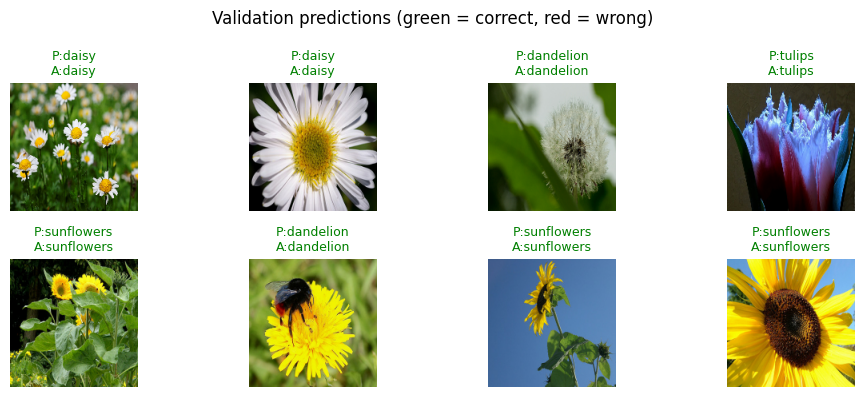

In [9]:
plt.figure(figsize=(10, 4))
for images, labels in val_ds.take(1):
    probs = model.predict(images, verbose=0)
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        p, t = int(probs[i].argmax()), int(labels[i].numpy())
        plt.title(
            f"P:{class_names[p]}\nA:{class_names[t]}",
            color="green" if p == t else "red", fontsize=9,
        )
        plt.axis("off")
plt.suptitle("Validation predictions (green = correct, red = wrong)")
plt.tight_layout()
plt.show()

## 7. Save the model and single-image inference utility

In [10]:
model.save("mobilenetv2_flowers.keras")
print("Saved model to mobilenetv2_flowers.keras")


def predict_image(image_path):
    img = keras.utils.load_img(image_path, target_size=IMG)
    arr = keras.utils.img_to_array(img)[None, ...]
    probs = model.predict(arr, verbose=0)[0]
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"{class_names[probs.argmax()]} ({probs.max():.1%})")
    plt.show()
    return dict(zip(class_names, probs.round(4)))

Saved model to mobilenetv2_flowers.keras
